In [1]:
import pandas as pd
from pgmpy.models import BayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator, HillClimbSearch, BicScore
from pgmpy.inference import VariableElimination
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, brier_score_loss
from sklearn.model_selection import train_test_split
import numpy as np
import time

In [2]:
file_path = 'assessment-item1/dementia_data-MRI-features.csv'
dementia_df = pd.read_csv(file_path)

dementia_df = dementia_df.drop(columns=['Subject ID', 'MRI ID'], errors='ignore')

dementia_df['Group'] = dementia_df['Group'].apply(lambda x: 1 if x == 'Demented' else 0)

for column in dementia_df.columns:
    if dementia_df[column].dtype in ['float64', 'int64']: 
        dementia_df[column].fillna(dementia_df[column].median(), inplace=True)
    else:  
        dementia_df[column].fillna(dementia_df[column].mode()[0], inplace=True)

C:\Users\msi 1\AppData\Local\Temp\ipykernel_21256\2010503193.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dementia_df[column].fillna(dementia_df[column].median(), inplace=True)
C:\Users\msi 1\AppData\Local\Temp\ipykernel_21256\2010503193.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [3]:
# Discretize continuous features
dementia_df['Age'] = pd.cut(dementia_df['Age'], bins=4, labels=False)
dementia_df['MMSE'] = pd.cut(dementia_df['MMSE'], bins=4, labels=False)
dementia_df['CDR'] = pd.cut(dementia_df['CDR'], bins=[-0.1, 0.25, 0.5, 1.0, 2.0], labels=False)
dementia_df['eTIV'] = pd.cut(dementia_df['eTIV'], bins=4, labels=False)
dementia_df['nWBV'] = pd.cut(dementia_df['nWBV'], bins=4, labels=False)
dementia_df['ASF'] = pd.cut(dementia_df['ASF'], bins=4, labels=False)

In [4]:
# Split data into training and testing sets
train_df, test_df = train_test_split(dementia_df, test_size=0.2, stratify=dementia_df['Group'], random_state=42)

In [5]:
# Hill Climb Search to learn Bayesian Network structure
hc = HillClimbSearch(train_df)
best_model = hc.estimate(scoring_method=BicScore(train_df))

# Define the model with the learned structure
learned_structure = BayesianNetwork(best_model.edges())


# Fit the model with Maximum Likelihood Estimation on the learned structure
start_train_time = time.time()
if 'Visit' not in learned_structure.nodes():
    learned_structure.add_node('Visit')
    learned_structure.add_edge('Visit', 'Group') # connecting Visit to Group; adjust based on your domain knowledge


learned_structure.fit(train_df, estimator=MaximumLikelihoodEstimator)
train_time = time.time() - start_train_time

# Initialize inference on the learned model
learned_inference = VariableElimination(learned_structure)

  0%|          | 0/1000000 [00:00<?, ?it/s]

In [6]:
# Define bins for continuous features
age_bins = pd.cut(dementia_df['Age'], bins=4, retbins=True)[1]
mmse_bins = pd.cut(dementia_df['MMSE'], bins=4, retbins=True)[1]
cdr_bins = pd.cut(dementia_df['CDR'], bins=[-0.1, 0.25, 0.5, 1.0, 2.0], retbins=True)[1]
etiv_bins = pd.cut(dementia_df['eTIV'], bins=4, retbins=True)[1]
nwbv_bins = pd.cut(dementia_df['nWBV'], bins=4, retbins=True)[1]
asf_bins = pd.cut(dementia_df['ASF'], bins=4, retbins=True)[1]

# Helper function to map continuous values to bins
def get_bin(value, bins):
    bin_index = pd.cut([value], bins=bins, labels=False)[0]
    return int(bin_index) if not pd.isna(bin_index) else int(len(bins) - 2 if value > bins[-1] else 0)


# Model Evaluation
y_true = test_df['Group'].values
y_pred = []
y_proba = []

# Start testing time
start_test_time = time.time()
for _, row in test_df.iterrows():
    # Convert continuous values to bins and prepare evidence
    evidence = {
        'Visit': row['Visit'],
        'Age': get_bin(row['Age'], age_bins),
        'EDUC': row['EDUC'],
        'SES': row['SES'],
        'MMSE': get_bin(row['MMSE'], mmse_bins),
        'CDR': get_bin(row['CDR'], cdr_bins),
        'eTIV': get_bin(row['eTIV'], etiv_bins),
        'nWBV': get_bin(row['nWBV'], nwbv_bins),
        'ASF': get_bin(row['ASF'], asf_bins)
    }
    
    try:
        query_result = learned_inference.query(variables=['Group'], evidence=evidence)
        prob = query_result.values[1]  # Probability of Group=1 (Demented)
        y_proba.append(prob)
        y_pred.append(1 if prob >= 0.5 else 0)
    except KeyError as e:
        print(f"KeyError for evidence {evidence}: {e}")

test_time = time.time() - start_test_time


In [7]:
# Run final query
# Slightly adjust evidence values to test sensitivity
adjusted_query_evidence = {
    'Visit': 2,
    'Age': get_bin(83, age_bins),  # Adjust age to see if results differ
    'EDUC': 12,
    'SES': 4,
    'MMSE': get_bin(29, mmse_bins),  
    'CDR': get_bin(0.5, cdr_bins),   
    'eTIV': get_bin(1701, etiv_bins),
    'nWBV': get_bin(0.711, nwbv_bins),
    'ASF': get_bin(1.032, asf_bins)
}

# Remove 'Visit' if it's not part of the learned structure
if 'Visit' not in learned_structure.nodes():
    adjusted_query_evidence.pop('Visit', None)
if 'SES' not in learned_structure.nodes():
    adjusted_query_evidence.pop('SES', None)    
if 'Age' not in learned_structure.nodes():
    adjusted_query_evidence.pop('Age', None)  
# Run the adjusted query
adjusted_query_result = learned_inference.query(variables=['Group'], evidence=adjusted_query_evidence)

print("Adjusted Conditional Probability for Group given modified evidence:")
for state, prob in zip(adjusted_query_result.state_names['Group'], adjusted_query_result.values):
    print(f"P(Group = {state} | adjusted evidence) = {prob:.4f}")


Adjusted Conditional Probability for Group given modified evidence:
P(Group = 0 | adjusted evidence) = 0.0720
P(Group = 1 | adjusted evidence) = 0.9280


In [8]:
# Calculate Metrics
accuracy = accuracy_score(y_true, y_pred)
auc_score = roc_auc_score(y_true, y_proba)
kl_divergence = log_loss(y_true, y_proba)  # Log Loss approximates KL Divergence in binary classification
brier_score = brier_score_loss(y_true, y_proba)

# Print Results
print("Model Evaluation Metrics for Bayesian Network with Hill Climb Structure Learning:")
print(f"Accuracy: {accuracy:.4f}")
print(f"AUC: {auc_score:.4f}")
print(f"Kullback-Leibler Divergence (Log Loss): {kl_divergence:.4f}")
print(f"Brier Score: {brier_score:.4f}")
print(f"Training Time: {train_time:.4f} seconds")
print(f"Testing Time: {test_time:.4f} seconds")


Model Evaluation Metrics for Bayesian Network with Hill Climb Structure Learning:
Accuracy: 0.9333
AUC: 0.9457
Kullback-Leibler Divergence (Log Loss): 2.4029
Brier Score: 0.0667
Training Time: 0.0180 seconds
Testing Time: 0.0845 seconds


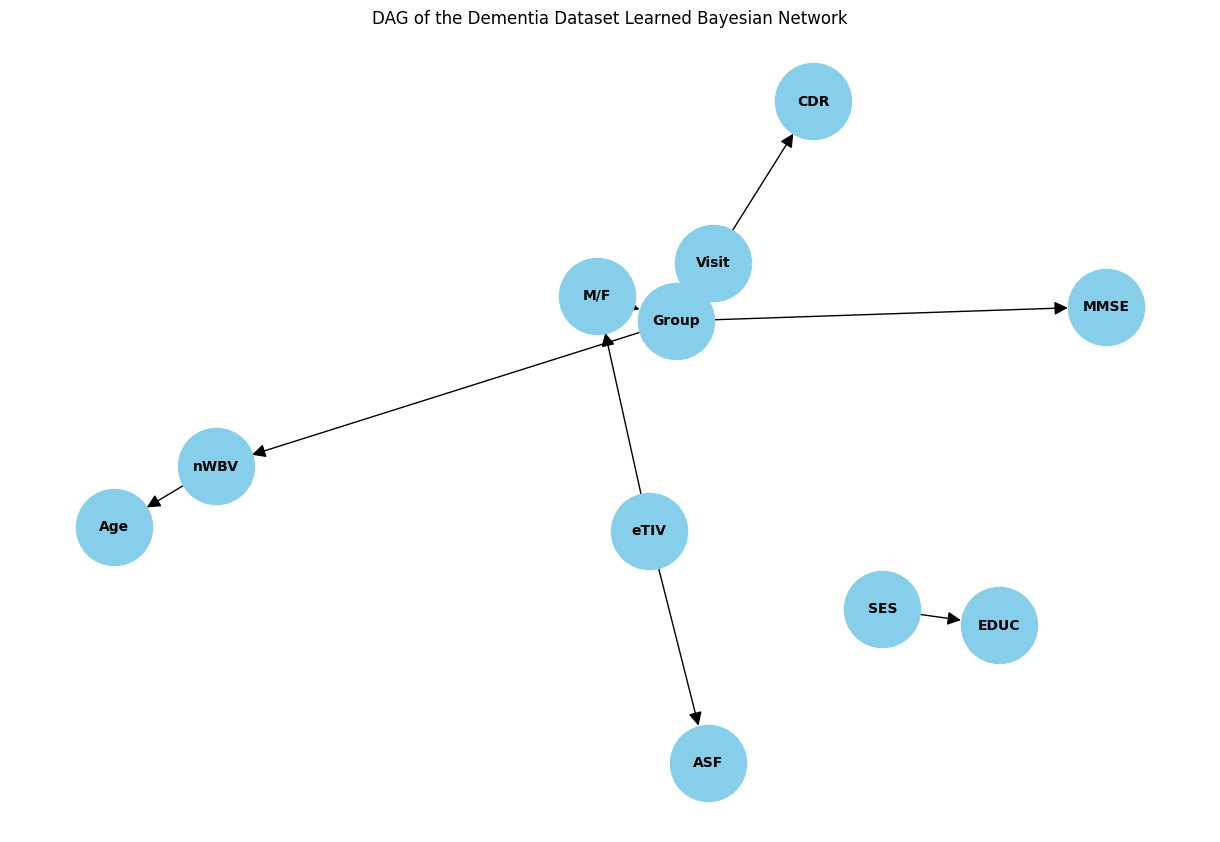

In [10]:
import matplotlib.pyplot as plt
import networkx as nx
from pgmpy.models import BayesianNetwork
plt.figure(figsize=(12, 8))
G = nx.DiGraph()
G.add_edges_from(learned_structure.edges())
pos = nx.spring_layout(G)  
nx.draw(G, pos, with_labels=True, node_size=3000, node_color="skyblue", font_size=10, font_weight="bold", arrowsize=20)
plt.title("DAG of the Dementia Dataset Learned Bayesian Network")
plt.show()